# Data Wrangling Project
## RQ: How does a ratio of specific sleep stages and their duration influence the sleep quality of a person? How do they influence the person’s stress level?
Group 114: Mikolaj Duchlinski, Danil Govorov, Emilis Masalskis, Zefan B. Morsen

### Libraries
First things first, as in all data projects, we do need to import important libraries for this project, as below.

In [409]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.options.display.max_rows = 20
np.set_printoptions(precision=4, suppress=True)
import seaborn as sns
from sklearn.metrics import r2_score
from sklearn.linear_model import LinearRegression


## Loading datasets that will be used in order to answer the Research question

In [410]:
sleep_efficiency = pd.read_csv("Sleep_Efficiency.csv")

sleep_analysis = pd.read_csv("wearable_tech_sleep_quality_1.csv")

## 1st dataset exploration and cleaning

In [411]:
sleep_efficiency.head(15)

,ID,Age,Gender,Bedtime,Wakeup time,Sleep duration,Sleep efficiency,REM sleep percentage,Deep sleep percentage,Light sleep percentage,Awakenings,Caffeine consumption,Alcohol consumption,Smoking status,Exercise frequency
0,1,65,Female,2021-03-06 01:00:00,2021-03-06 07:00:00,6.0,0.88,18,70,12,0.0,0.0,0.0,Yes,3.0
1,2,69,Male,2021-12-05 02:00:00,2021-12-05 09:00:00,7.0,0.66,19,28,53,3.0,0.0,3.0,Yes,3.0
2,3,40,Female,2021-05-25 21:30:00,2021-05-25 05:30:00,8.0,0.89,20,70,10,1.0,0.0,0.0,No,3.0
3,4,40,Female,2021-11-03 02:30:00,2021-11-03 08:30:00,6.0,0.51,23,25,52,3.0,50.0,5.0,Yes,1.0
4,5,57,Male,2021-03-13 01:00:00,2021-03-13 09:00:00,8.0,0.76,27,55,18,3.0,0.0,3.0,No,3.0
5,6,36,Female,2021-07-01 21:00:00,2021-07-01 04:30:00,7.5,0.90,23,60,17,0.0,NaN,0.0,No,1.0
6,7,27,Female,2021-07-21 21:00:00,2021-07-21 03:00:00,6.0,0.54,28,25,47,2.0,50.0,0.0,Yes,1.0
7,8,53,Male,2021-08-16 00:30:00,2021-08-16 10:30:00,10.0,0.90,28,52,20,0.0,50.0,0.0,Yes,3.0
8,9,41,Female,2021-04-05 02:30:00,2021-04-05 08:30:00,6.0,0.79,28,55,17,3.0,50.0,0.0,No,1.0
9,10,11,Female,2021-09-16 01:00:00,2021-09-16 10:00:00,9.0,0.55,18,37,45,4.0,0.0,0.0,No,0.0


In [412]:
duplicate_rows = sleep_efficiency[sleep_efficiency.duplicated()]
print("Duplicate Rows:")
print(duplicate_rows)

Duplicate Rows:
Empty DataFrame
Columns: [ID, Age, Gender, Bedtime, Wakeup time, Sleep duration, Sleep efficiency, REM sleep percentage, Deep sleep percentage, Light sleep percentage, Awakenings, Caffeine consumption, Alcohol consumption, Smoking status, Exercise frequency]
Index: []


### No duplicates, therefore we can continue

In [413]:
sleep_efficiency.isnull().sum()

ID                         0
Age                        0
Gender                     0
Bedtime                    0
Wakeup time                0
Sleep duration             0
Sleep efficiency           0
REM sleep percentage       0
Deep sleep percentage      0
Light sleep percentage     0
Awakenings                20
Caffeine consumption      25
Alcohol consumption       14
Smoking status             0
Exercise frequency         6
dtype: int64

### "Awakenings", "Caffeine consumption" and "Alcohol consumption" do contain null values, however, Only "Awakenings" variable will matter to our analysis

In [414]:
rows_nan = sleep_efficiency[pd.isna(sleep_efficiency["Awakenings"])]
rows_nan

,ID,Age,Gender,Bedtime,Wakeup time,Sleep duration,Sleep efficiency,REM sleep percentage,Deep sleep percentage,Light sleep percentage,Awakenings,Caffeine consumption,Alcohol consumption,Smoking status,Exercise frequency
19,20,52,Male,2021-12-03 00:30:00,2021-12-03 07:30:00,7.0,0.89,28,52,20,NaN,50.0,0.0,Yes,3.0
85,86,53,Male,2021-11-06 23:00:00,2021-11-06 06:30:00,7.5,0.88,18,65,17,NaN,75.0,0.0,No,2.0
123,124,19,Male,2021-10-05 01:30:00,2021-10-05 10:00:00,8.5,0.91,20,67,13,NaN,25.0,0.0,Yes,1.0
135,136,48,Female,2021-02-03 00:00:00,2021-02-03 07:00:00,7.0,0.82,20,65,15,NaN,50.0,1.0,No,4.0
138,139,55,Male,2021-03-01 02:30:00,2021-03-01 10:00:00,7.5,0.83,23,58,19,NaN,0.0,3.0,No,3.0
143,144,25,Male,2021-04-21 21:30:00,2021-04-21 04:30:00,7.0,0.87,27,55,18,NaN,0.0,3.0,No,3.0
149,150,33,Female,2021-09-30 02:30:00,2021-09-30 10:00:00,7.5,0.60,24,25,51,NaN,50.0,0.0,No,1.0
170,171,24,Male,2021-10-20 21:30:00,2021-10-20 05:30:00,8.0,0.89,27,55,18,NaN,0.0,3.0,No,3.0
244,245,37,Female,2021-01-08 22:00:00,2021-01-08 05:00:00,7.0,0.92,24,59,17,NaN,0.0,0.0,No,4.0
249,250,61,Male,2021-04-04 00:30:00,2021-04-04 10:30:00,10.0,0.66,19,28,53,NaN,0.0,4.0,No,1.0


In [415]:
sleep_efficiency = sleep_efficiency.fillna("0.0") # Replacing Null values with 0.0, as that would mean.


### Analyzing distribution of Sleep efficiency

In [416]:
# Defining the bins for showing a good dsitribution
bins = np.arange(0, 1.1, 0.1)
labels = [f"{int(bins[i]*100)}-{int(bins[i+1]*100)}%" for i in range(len(bins)-1)]

sleep_efficiency["Sleep Efficiency Range"] = pd.cut(sleep_efficiency["Sleep efficiency"], bins=bins, labels=labels, include_lowest=True)

sleep_efficiency_distribution = sleep_efficiency["Sleep Efficiency Range"].value_counts().sort_index()
print(sleep_efficiency_distribution)


Sleep Efficiency Range
0-10%        0
10-20%       0
20-30%       0
30-40%       0
40-50%       8
50-60%      53
60-70%      55
70-80%      90
80-90%     140
90-100%    106
Name: count, dtype: int64


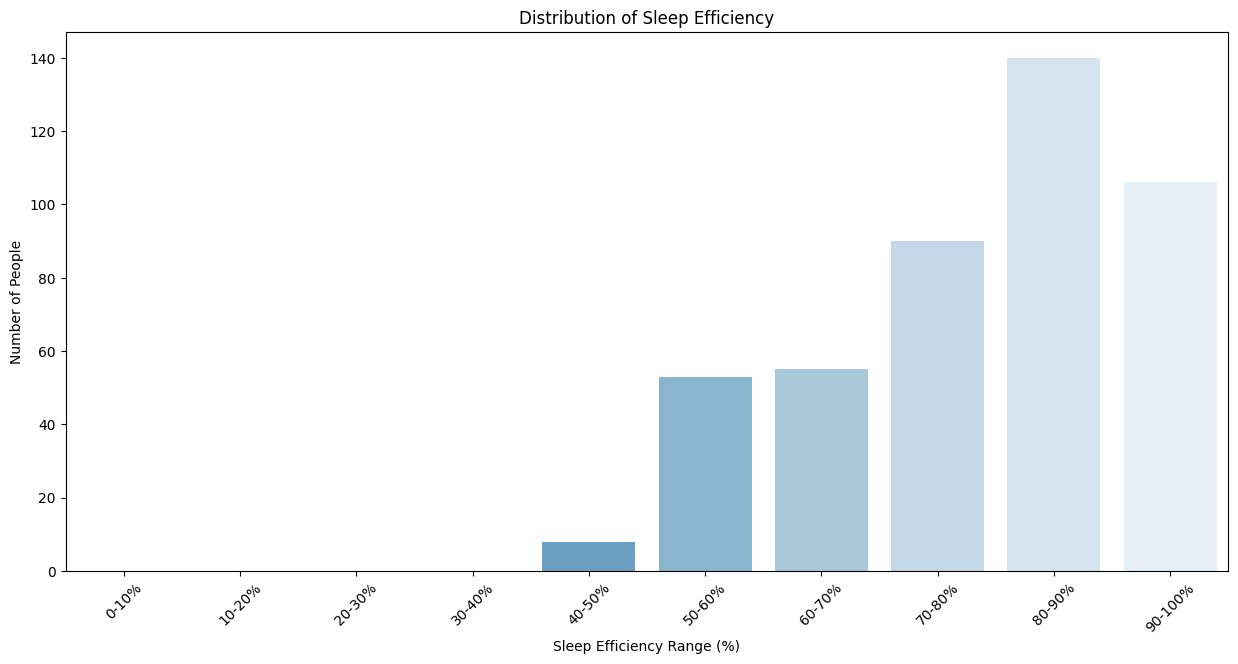

In [417]:
plt.figure(figsize=(15, 7))
sns.barplot(
    x=sleep_efficiency_distribution.index, 
    y=sleep_efficiency_distribution.values, 
    hue=sleep_efficiency_distribution.index,
    palette="Blues_r",
    legend=False
)

plt.xlabel("Sleep Efficiency Range (%)")
plt.ylabel("Number of People")
plt.title("Distribution of Sleep Efficiency")
plt.xticks(rotation=45)
plt.show()

### We can notice here that the Sleep efficiency in our dataset is quite good on average, big majority of above 70% Sleep efficiency

## Finding a correlation of variables in the equation
### Heatmap visualization of correlation of "Sleep efficiancy", "REM sleep percentage", "Light sleep percentage", "Deep sleep percentage" and "Awakenings"

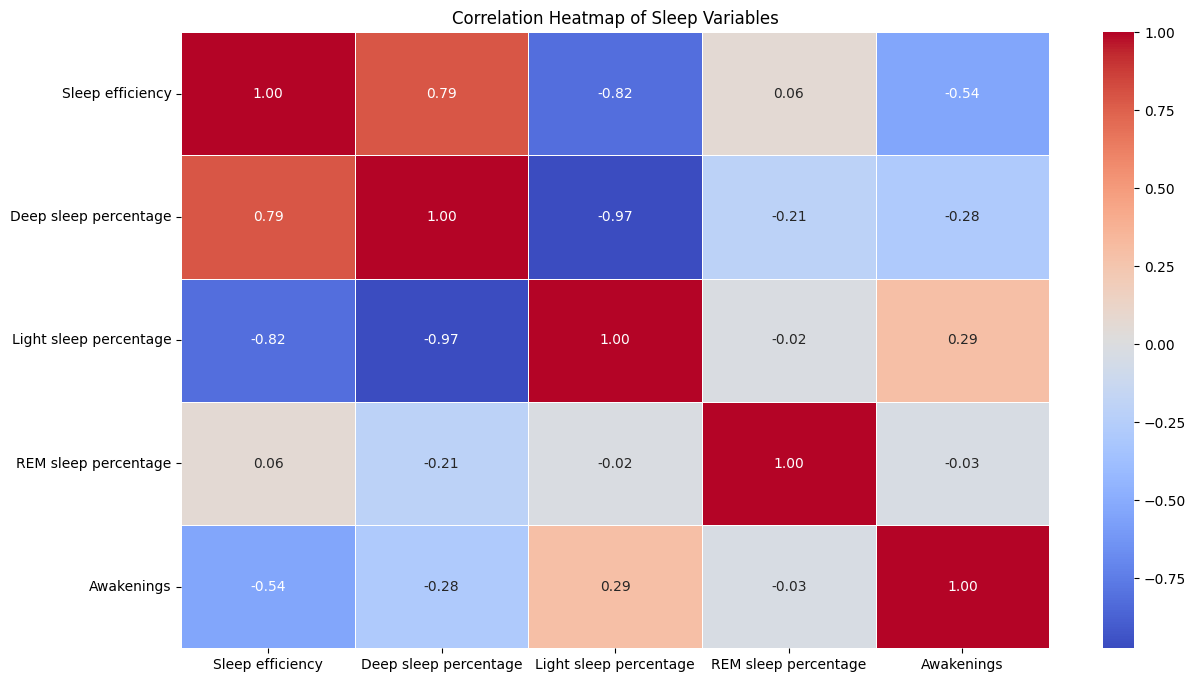

In [418]:
import numpy as np

selected_cols = ["Sleep efficiency", "Deep sleep percentage", "Light sleep percentage", 
                 "REM sleep percentage", "Awakenings"]

correlation_matrix = sleep_efficiency[selected_cols].corr()

plt.figure(figsize=(14, 8))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap of Sleep Variables")
plt.show()

### Analyzing correlation of sleep stage percentages to Sleep efficiency

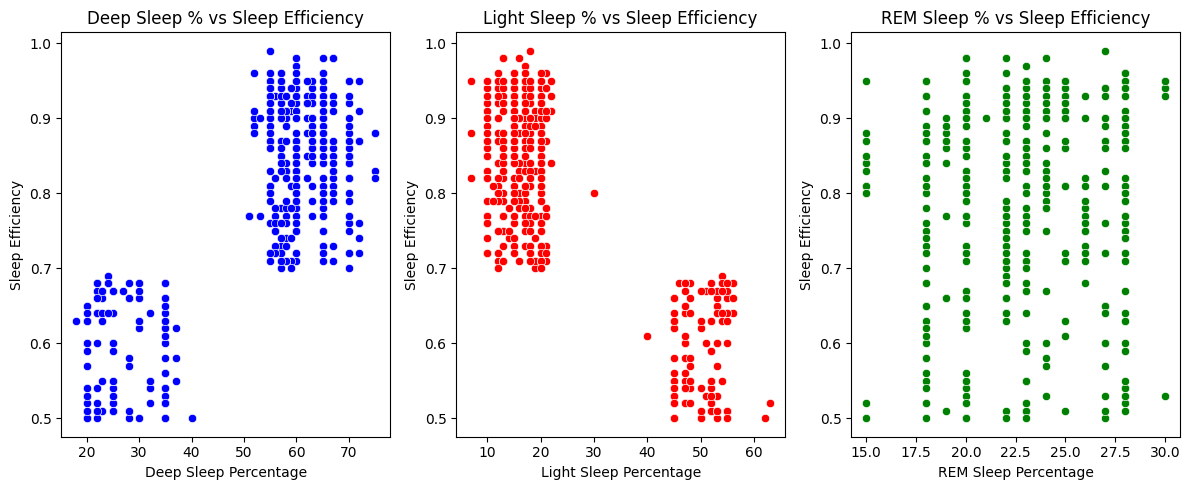

In [419]:
fig, axes = plt.subplots(1, 3, figsize=(12, 5))

# Deep Sleep vs. Sleep Efficiency
sns.scatterplot(ax=axes[0], x=sleep_efficiency["Deep sleep percentage"], y=sleep_efficiency["Sleep efficiency"], color="blue")
axes[0].set_title("Deep Sleep % vs Sleep Efficiency")
axes[0].set_xlabel("Deep Sleep Percentage")
axes[0].set_ylabel("Sleep Efficiency")

# Light Sleep vs. Sleep Efficiency
sns.scatterplot(ax=axes[1], x=sleep_efficiency["Light sleep percentage"], y=sleep_efficiency["Sleep efficiency"], color="red")
axes[1].set_title("Light Sleep % vs Sleep Efficiency")
axes[1].set_xlabel("Light Sleep Percentage")
axes[1].set_ylabel("Sleep Efficiency")

# REM stage Sleep vs. Sleep Efficiency
sns.scatterplot(ax=axes[2], x=sleep_efficiency["REM sleep percentage"], y=sleep_efficiency["Sleep efficiency"], color="green")
axes[2].set_title("REM Sleep % vs Sleep Efficiency")
axes[2].set_xlabel("REM Sleep Percentage")
axes[2].set_ylabel("Sleep Efficiency")

plt.tight_layout()
plt.show()


## It can be noticed that REM stage of sleep does not influence the Sleep efficiency that directly.
Instead Deep stage of sleep and Light stage of sleep both have quite big influence on the efficiency of sleeping. Clearly Deep sleep seem to be the moment when the human body and mind do really rest. With Deep sleep percentages over 50 %, the Sleep efficiancy rises significantly. Moreover, we can notice the corresponding reflection on Light Sleep percentage correlation to Sleep efficiancy

In [420]:
from sklearn.linear_model import LinearRegression

X = sleep_efficiency[["Deep sleep percentage", "Light sleep percentage", "Awakenings"]]
y = sleep_efficiency["Sleep efficiency"]

model = LinearRegression()
model.fit(X, y)

# Extract coefficients and intercept
coefficients = model.coef_
intercept = model.intercept_

print("Equation for Sleep Efficiency:")
print(f"SE = {coefficients[0]:.4f} * Deep Sleep % + {coefficients[1]:.4f} * Light Sleep % + {coefficients[2]:.4f} * Awakenings + {intercept:.4f}")


Equation for Sleep Efficiency:
SE = -0.0016 * Deep Sleep % + -0.0079 * Light Sleep % + -0.0321 * Awakenings + 1.1163


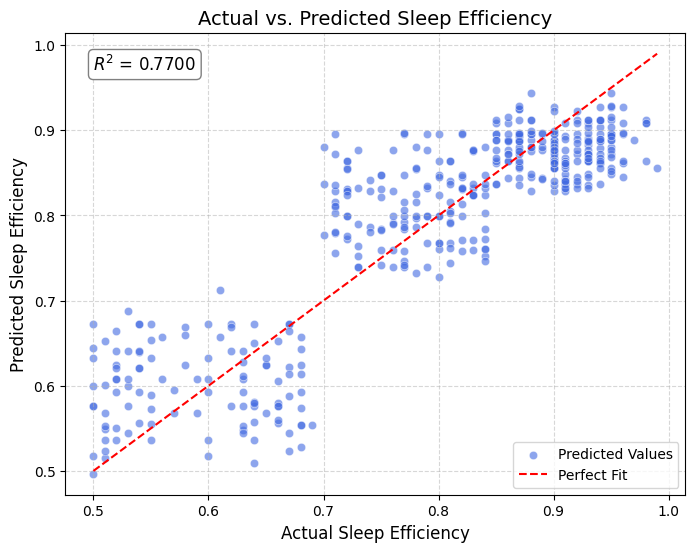

In [421]:
y_pred = model.predict(X) #Predict values with the model using our Linear Regeression equation from above

# Compute R² score
r2 = r2_score(y, y_pred)

plt.figure(figsize=(8, 6))

sns.scatterplot(x=y, y=y_pred, color="royalblue", alpha=0.6, label="Predicted Values")

plt.plot([min(y), max(y)], [min(y), max(y)], linestyle='--', color='red', label="Perfect Fit")

plt.xlabel("Actual Sleep Efficiency", fontsize=12)
plt.ylabel("Predicted Sleep Efficiency", fontsize=12)
plt.title("Actual vs. Predicted Sleep Efficiency", fontsize=14)

plt.text(min(y), max(y) * 0.98, f"$R^2$ = {r2:.4f}", fontsize=12, color="black", bbox=dict(facecolor='white', edgecolor='gray', boxstyle='round,pad=0.3'))

plt.legend(loc='lower right')
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


## 2nd dataset wrangling and cleaning

In [422]:
sleep_analysis.head(20)


,Heart_Rate_Variability,Body_Temperature,Movement_During_Sleep,Sleep_Duration_Hours,Sleep_Quality_Score,Caffeine_Intake_mg,Stress_Level,Bedtime_Consistency,Light_Exposure_hours
0,79.934283,37.199678,1.324822,4.638289,1.000000,107.624032,2.771837,0.657037,7.933949
1,67.234714,36.962317,1.855481,6.209422,1.000000,104.658589,3.738138,0.144464,6.992699
2,82.953771,36.529815,1.207580,6.879592,10.000000,0.000000,3.115880,0.642949,7.655250
3,100.460597,36.176532,1.692038,10.331531,1.000000,116.990981,3.904008,0.453255,9.429463
4,65.316933,36.849112,0.106385,8.334830,1.000000,223.282908,4.571699,0.641492,10.555713
5,65.317261,36.696743,2.213294,5.496778,7.122153,22.576788,6.674309,0.655386,9.140975
6,101.584256,36.947597,2.001205,8.229054,1.000000,254.848265,4.357682,0.821583,8.203446
7,85.348695,36.817586,1.182911,5.179044,1.000000,198.777482,1.828749,0.770691,10.996024
8,60.610512,37.024776,2.659246,9.124037,2.409237,76.576668,7.280136,0.769314,7.374327
9,80.851201,36.232382,2.937570,6.793313,1.000000,135.847036,3.325820,0.788734,10.061839


In [423]:
sleep_analysis.isnull().sum()

Heart_Rate_Variability    0
Body_Temperature          0
Movement_During_Sleep     0
Sleep_Duration_Hours      0
Sleep_Quality_Score       0
Caffeine_Intake_mg        0
Stress_Level              0
Bedtime_Consistency       0
Light_Exposure_hours      0
dtype: int64

### No null values

In [424]:
duplicate_rows = sleep_analysis[sleep_analysis.duplicated()]
print("Duplicate Rows:")
print(duplicate_rows)

Duplicate Rows:
Empty DataFrame
Columns: [Heart_Rate_Variability, Body_Temperature, Movement_During_Sleep, Sleep_Duration_Hours, Sleep_Quality_Score, Caffeine_Intake_mg, Stress_Level, Bedtime_Consistency, Light_Exposure_hours]
Index: []


### No duplicates

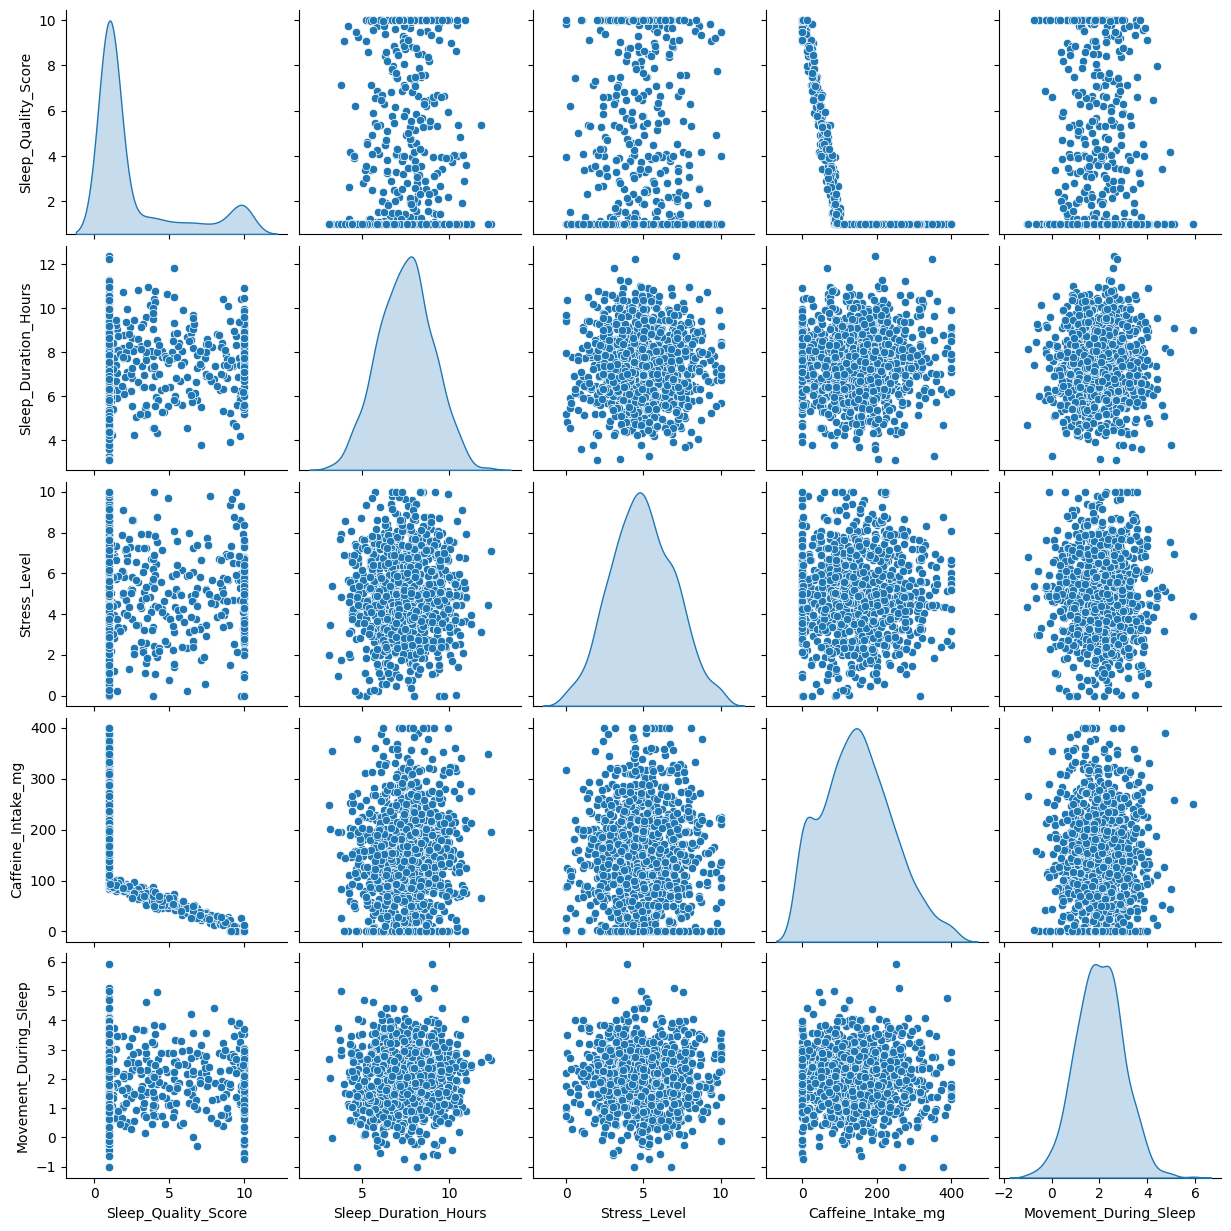

In [425]:
sns.pairplot(sleep_analysis[["Sleep_Quality_Score", "Sleep_Duration_Hours", "Stress_Level", "Caffeine_Intake_mg", "Movement_During_Sleep"]], diag_kind="kde")
plt.show()

## Finding a correlation of variables in the equation
### Now let's start with a correlation heatmap, in order to notice which values influence each other strongly

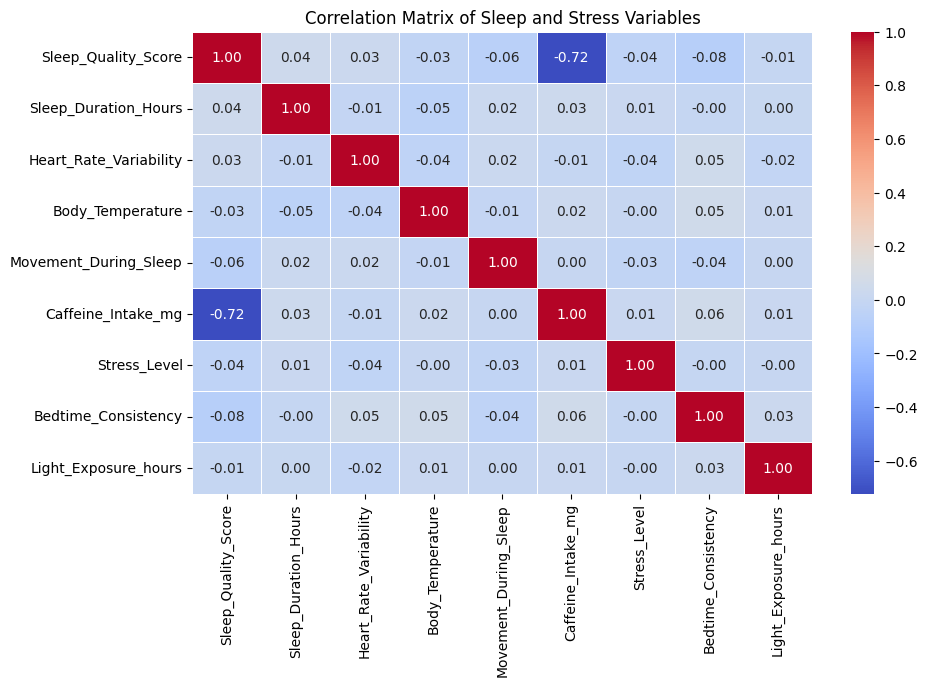

In [426]:
relevant_cols = [
    "Sleep_Quality_Score", "Sleep_Duration_Hours", "Heart_Rate_Variability", "Body_Temperature",
    "Movement_During_Sleep", "Caffeine_Intake_mg", "Stress_Level", "Bedtime_Consistency", "Light_Exposure_hours"
]

correlation_matrix = sleep_analysis[relevant_cols].corr()

plt.figure(figsize=(10, 6))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)

plt.title("Correlation Matrix of Sleep and Stress Variables")
plt.show()


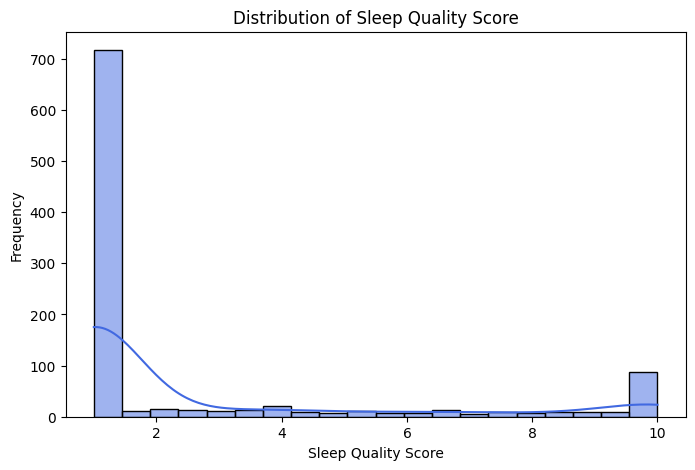

In [427]:
plt.figure(figsize=(8, 5))
sns.histplot(sleep_analysis["Sleep_Quality_Score"], bins=20, kde=True, color="royalblue")
plt.xlabel("Sleep Quality Score")
plt.ylabel("Frequency")
plt.title("Distribution of Sleep Quality Score")
plt.show()



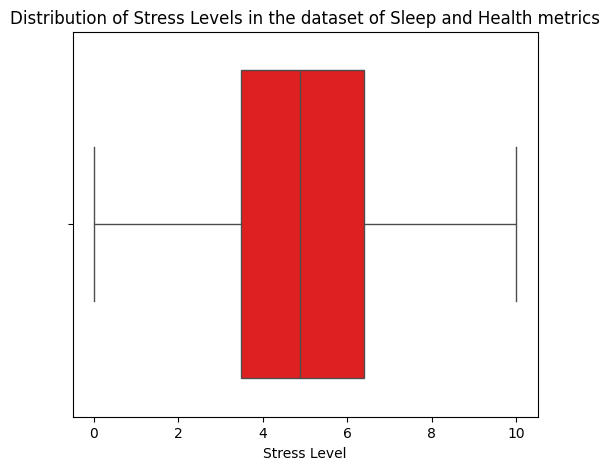

In [428]:
plt.figure(figsize=(6, 5))
sns.boxplot(x=sleep_analysis["Stress_Level"], color="red")
plt.xlabel("Stress Level")
plt.title("Distribution of Stress Levels in the dataset of Sleep and Health metrics")
plt.show()



## Sleep stage do not interfere Stress levels directly

# Follow-up Research question
## Can you predict someone’s stress level based on sleep data, using smartwatch hearth and sleep tracking technology?

We are going to try to achieve an answer to that question.

To accomplish such a goal, we will need to train a model on our previous datasets, so that the model can detect stress levels, based on important sleep characteristics (duration and quality of sleep, percentage of each sleep stage).
1. Firstly, we do need to split the datasets into train and test partitions.
2. Secondly, we do need to find the right model for training on this particular dataset. (I do already know the answer based on the research of approach towards this topic in the web, but we would like to still test them).
3. Thirdly, choose the correct hyperparameters for the model.
Fourthly, try predicting stress levels on datasets below.

### Importing important modules

In [429]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score

from sklearn.linear_model import LogisticRegression    
from sklearn.ensemble import RandomForestClassifier    
from sklearn.tree import DecisionTreeClassifier        
from sklearn import svm                         
from sklearn.naive_bayes import GaussianNB            
from sklearn.neighbors import KNeighborsClassifier  

from scipy.spatial import cKDTree  # Used for nearest neighbor matching in merging 2 datasets

## Merging 2 datasets

In [430]:
sleep_efficiency.columns = sleep_efficiency.columns.str.strip()
sleep_analysis.columns = sleep_analysis.columns.str.strip()

# Ensure all column names are strings (To not run into Key errors)
sleep_efficiency.columns = sleep_efficiency.columns.astype(str)
sleep_analysis.columns = sleep_analysis.columns.astype(str)

sleep_efficiency_selected = sleep_efficiency.loc[:, ["Sleep duration", "Sleep efficiency", 
                                                     "REM sleep percentage", "Deep sleep percentage", 
                                                     "Light sleep percentage"]].copy()

sleep_analysis_selected = sleep_analysis.loc[:, ["Heart_Rate_Variability", "Sleep_Duration_Hours", "Sleep_Quality_Score", "Stress_Level"]].copy()

sleep_analysis_selected.rename(columns={"Sleep_Duration_Hours": "Sleep duration", 
                                        "Sleep_Quality_Score": "Sleep efficiency",
                                        "Stress_Level": "Stress level"}, inplace=True)

sleep_analysis_selected["Sleep efficiency"] = sleep_analysis_selected["Sleep efficiency"] / 10.0  # Rescale to 0-1 range, in order to fix the mismatch of Sleep efficiancy values between 2 datasets

# Rounding "Sleep duration" values to improve matching
sleep_efficiency_selected["Sleep duration"] = sleep_efficiency_selected["Sleep duration"].round(1)
sleep_analysis_selected["Sleep duration"] = sleep_analysis_selected["Sleep duration"].round(1)

# Apply fuzzy matching for "Sleep duration" (nearest neighbor matching)
tree = cKDTree(sleep_analysis_selected[["Sleep duration"]].values)
_, idxs = tree.query(sleep_efficiency_selected[["Sleep duration"]].values, k=1)

wearable_tech_matched = sleep_analysis_selected.iloc[idxs].reset_index(drop=True)

merged_df = pd.concat([sleep_efficiency_selected.reset_index(drop=True), wearable_tech_matched], axis=1)

merged_df = merged_df.loc[:, ~merged_df.columns.duplicated()]

merged_df.to_csv("Merged_Sleep_Data.csv", index=True)
print(merged_df.head(10))


   Sleep duration  Sleep efficiency  REM sleep percentage  \
0             6.0              0.88                    18   
1             7.0              0.66                    19   
2             8.0              0.89                    20   
3             6.0              0.51                    23   
4             8.0              0.76                    27   
5             7.5              0.90                    23   
6             6.0              0.54                    28   
7            10.0              0.90                    28   
8             6.0              0.79                    28   
9             9.0              0.55                    18   

   Deep sleep percentage  Light sleep percentage  Heart_Rate_Variability  \
0                     70                      12               89.686448   
1                     28                      53               86.463412   
2                     70                      10               81.451656   
3                     25

### Correlation matrix for merged datasets

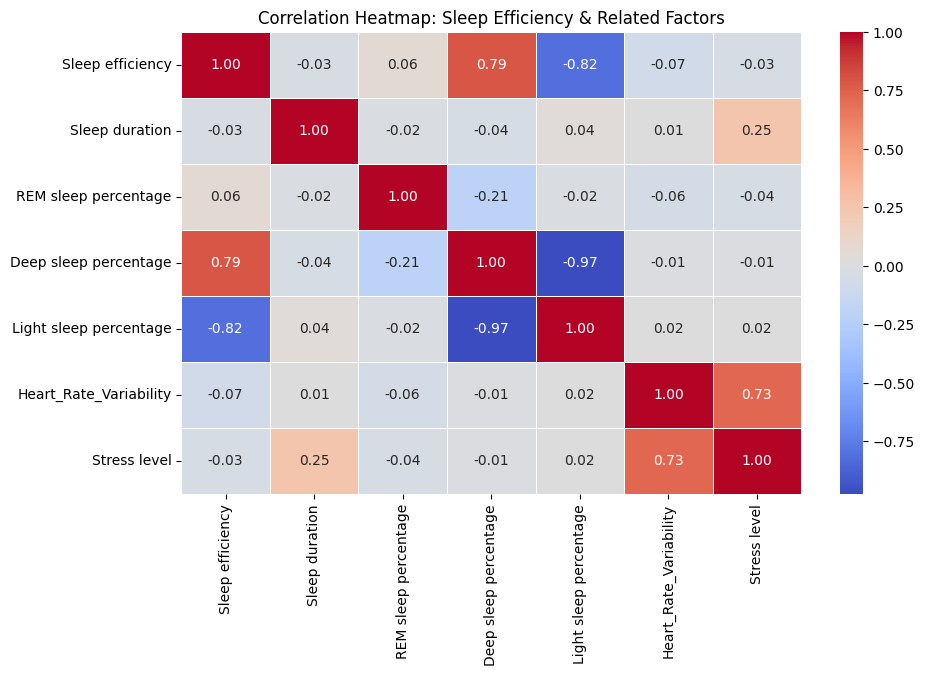

In [431]:
merged_df = pd.read_csv("Merged_Sleep_Data.csv")

columns_to_plot = ["Sleep efficiency", "Sleep duration", "REM sleep percentage", 
                   "Deep sleep percentage", "Light sleep percentage", "Heart_Rate_Variability", "Stress level"]

corr_matrix = merged_df[columns_to_plot].corr()

plt.figure(figsize=(10, 6))
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Correlation Heatmap: Sleep Efficiency & Related Factors")
plt.show()


### Pariplot for merged datasets

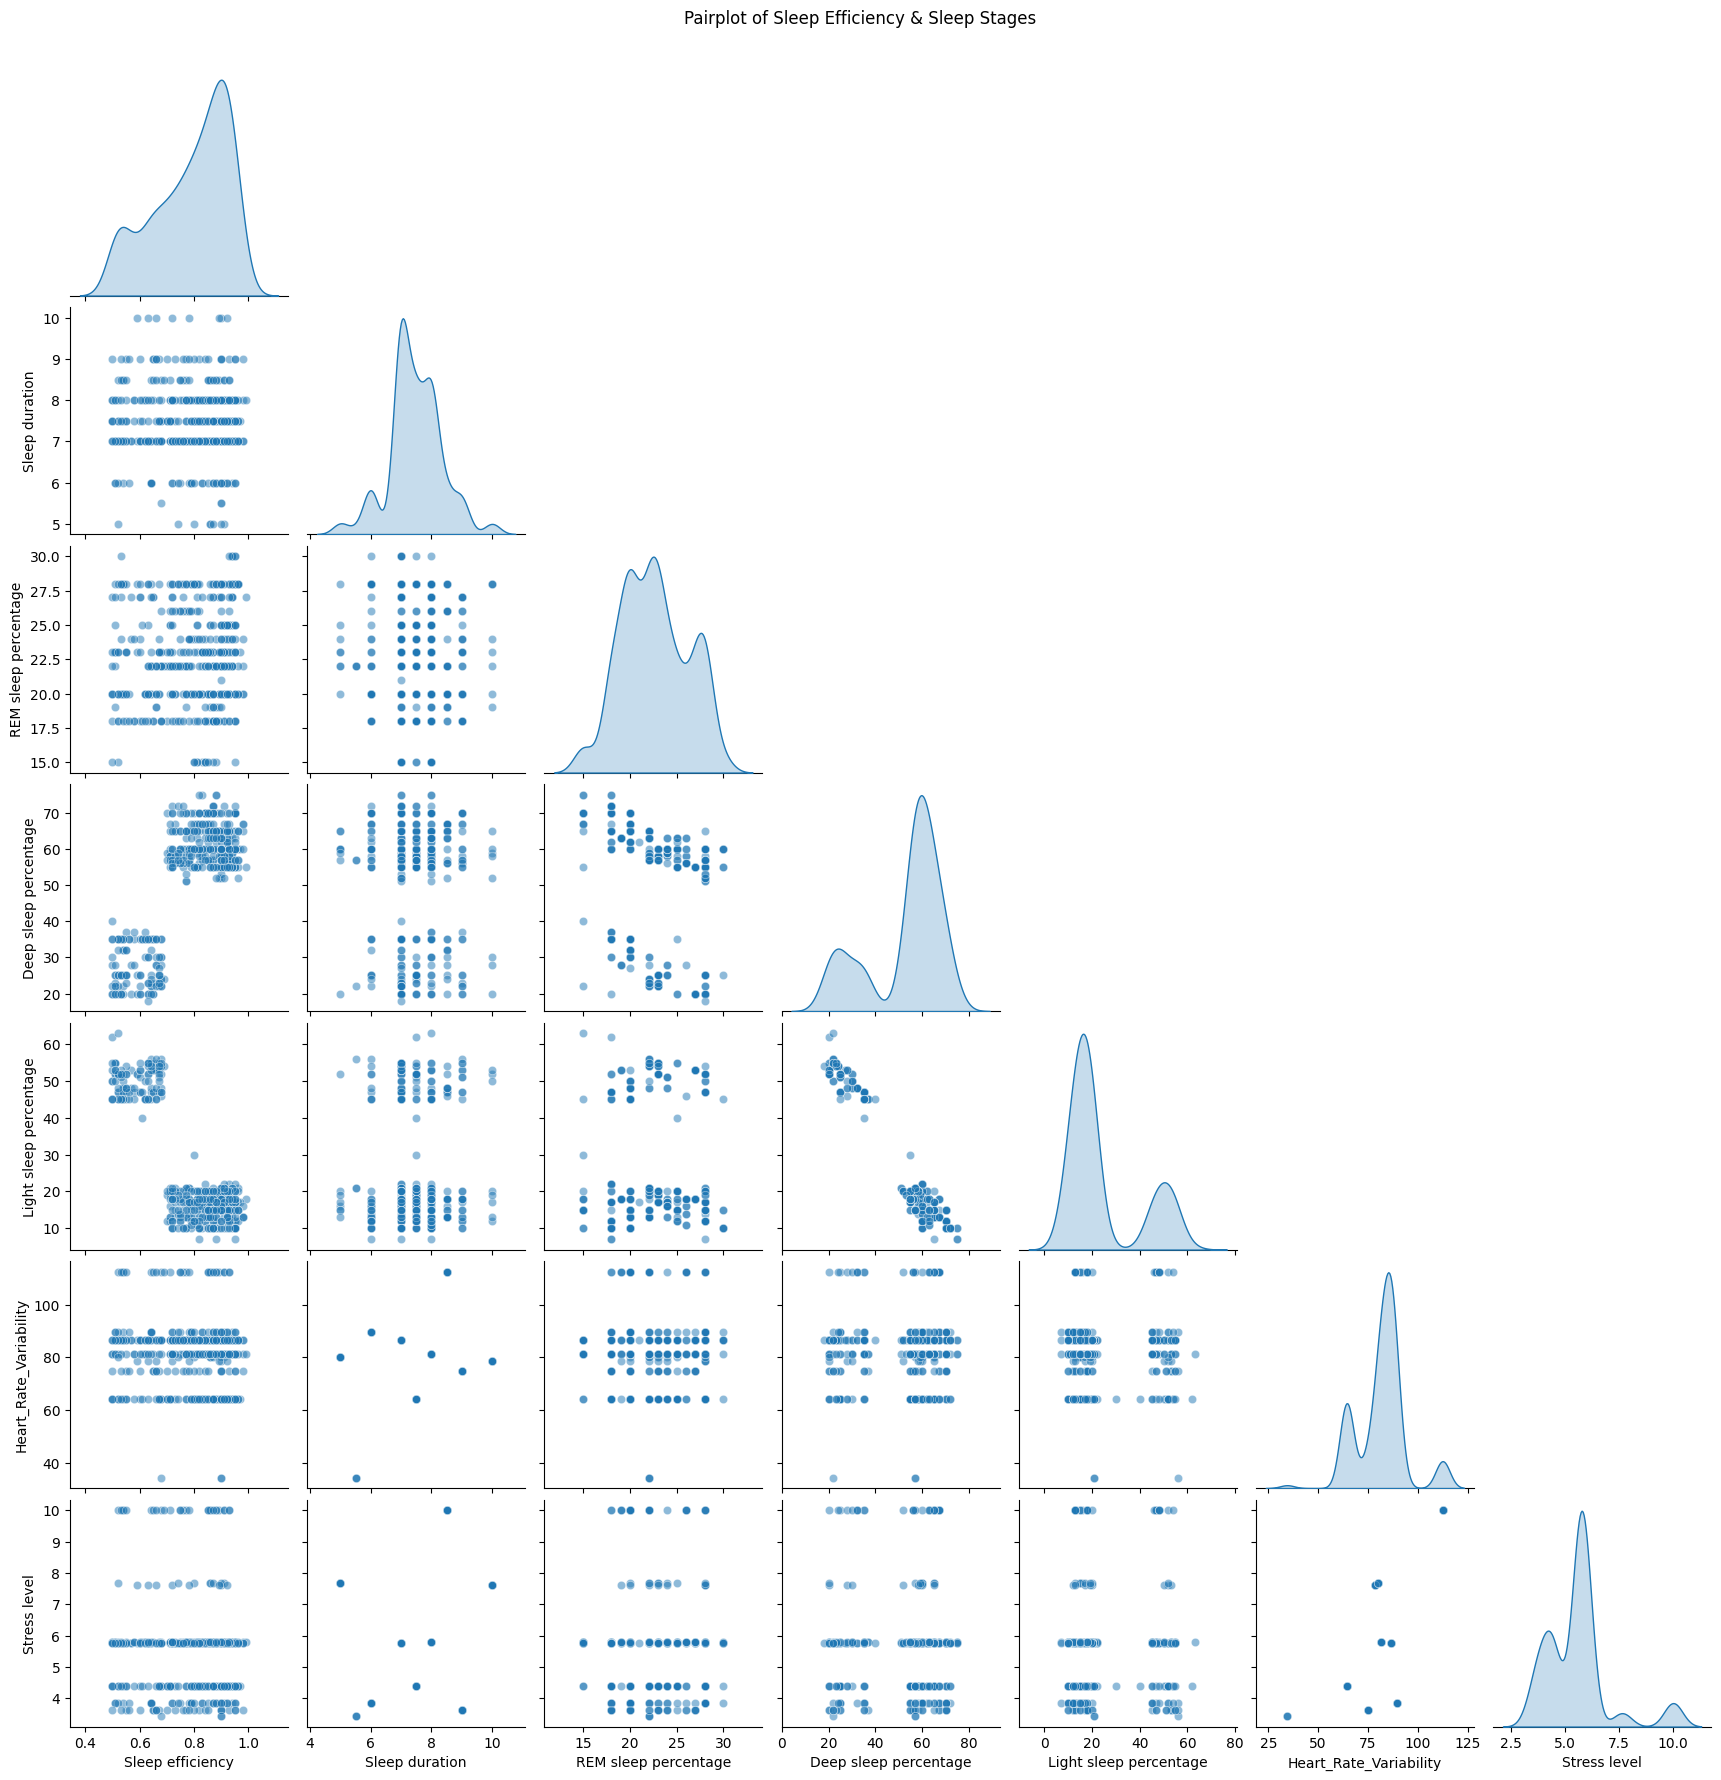

In [432]:
sns.pairplot(merged_df[columns_to_plot], diag_kind="kde", corner=True, plot_kws={"alpha": 0.5})
plt.suptitle("Pairplot of Sleep Efficiency & Sleep Stages", y=1.02)
plt.show()


### Preparing the data for training

In [433]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVR
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

merged_df = pd.read_csv("Merged_Sleep_Data.csv")

print(merged_df.info())
print(merged_df.head())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 452 entries, 0 to 451
Data columns (total 8 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Unnamed: 0              452 non-null    int64  
 1   Sleep duration          452 non-null    float64
 2   Sleep efficiency        452 non-null    float64
 3   REM sleep percentage    452 non-null    int64  
 4   Deep sleep percentage   452 non-null    int64  
 5   Light sleep percentage  452 non-null    int64  
 6   Heart_Rate_Variability  452 non-null    float64
 7   Stress level            452 non-null    float64
dtypes: float64(4), int64(4)
memory usage: 28.4 KB
None
   Unnamed: 0  Sleep duration  Sleep efficiency  REM sleep percentage  \
0           0             6.0              0.88                    18   
1           1             7.0              0.66                    19   
2           2             8.0              0.89                    20   
3           3     

## Regression models

In [434]:
y = merged_df["Stress level"]

X = merged_df[["Sleep efficiency", "Sleep duration", "REM sleep percentage", 
               "Deep sleep percentage", "Light sleep percentage", "Heart_Rate_Variability"]]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

X_train shape: (361, 6)
y_train shape: (361,)
X_test shape: (91, 6)
y_test shape: (91,)


### Classic Linear Regression model

In [435]:
model_linear_regression = LinearRegression()
model_linear_regression.fit(X_train, y_train)

linear_regression_pred = model_linear_regression.predict(X_test)

Model Performance:
RMSE: 0.90
R² Score: 0.60


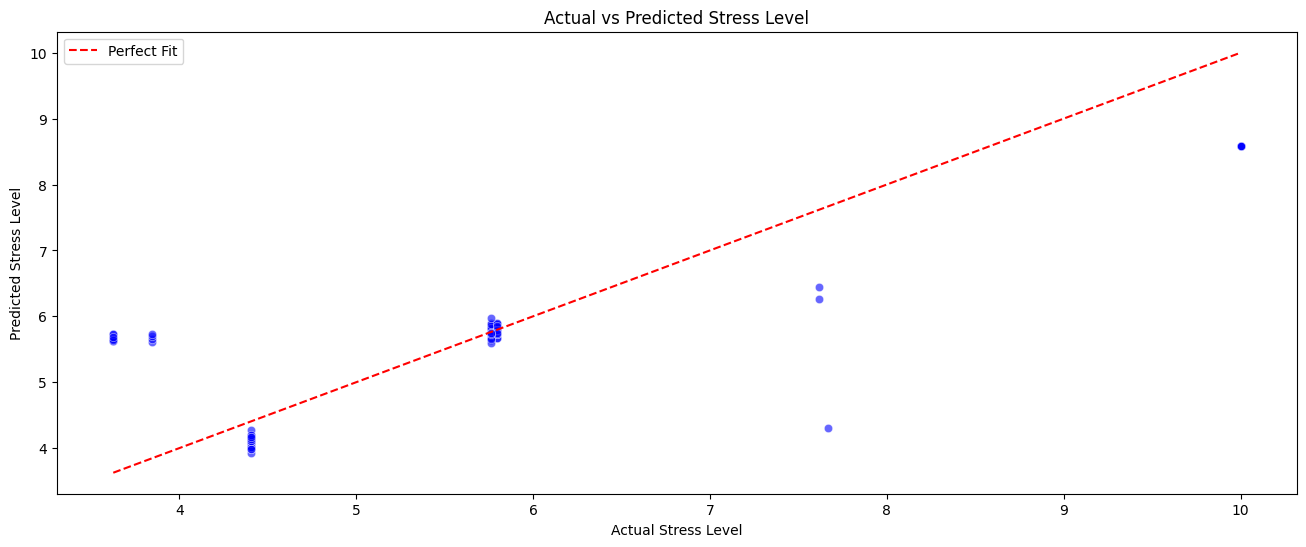

In [436]:
rmse = np.sqrt(mean_squared_error(y_test, linear_regression_pred))
r2 = r2_score(y_test, linear_regression_pred)

print(f"Model Performance:\nRMSE: {rmse:.2f}\nR² Score: {r2:.2f}")

plt.figure(figsize=(16,6))
sns.scatterplot(x=y_test, y=linear_regression_pred, color="blue", alpha=0.6)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], linestyle='--', color='red', label="Perfect Fit")
plt.xlabel("Actual Stress Level")
plt.ylabel("Predicted Stress Level")
plt.title("Actual vs Predicted Stress Level")
plt.legend()
plt.show()


## Classification of Stress Levels (low, medium, high)

In [437]:
# For Classification models we do need to transform numerical values of Stress levels from the Merged dataset into classifixation labels
merged_classification = pd.read_csv("Merged_Sleep_Data.csv")

bins = [0.0, 5.0, 6.0, 10.1]
labels = ["Low", "Medium", "High"]
merged_classification["Stress_Level_Cat"] = pd.cut(merged_classification["Stress level"], bins=bins, labels=labels)


from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
merged_classification["Stress_Level_Cat"] = label_encoder.fit_transform(merged_classification["Stress_Level_Cat"])

X = merged_classification[["Sleep efficiency", "Sleep duration", "REM sleep percentage", 
               "Deep sleep percentage", "Light sleep percentage", "Heart_Rate_Variability"]]

y = merged_classification["Stress_Level_Cat"]  # Now categorical (0, 1, 2)

### Logistic Regression

Training the Logistic Regression model

In [438]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

model = LogisticRegression()
model.fit(X_train, y_train)

predicted = model.predict(X_test)

/opt/anaconda3/envs/Assignments/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:460: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Analyzing the trained classic Logistic Regression model

In [439]:
conf = confusion_matrix(y_test, predicted)
print("Confusion Matrix:\n", conf)

cr = classification_report(y_test, predicted)
print("Classification Report:\n", cr)

print("The test accuracy of Logistic Regression is:", accuracy_score(y_test, predicted) * 100, "%")

Confusion Matrix:
 [[ 7  1  1]
 [ 0 18 12]
 [ 0  0 52]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.78      0.88         9
           1       0.95      0.60      0.73        30
           2       0.80      1.00      0.89        52

    accuracy                           0.85        91
   macro avg       0.92      0.79      0.83        91
weighted avg       0.87      0.85      0.84        91

The test accuracy of Logistic Regression is: 84.61538461538461 %


### Naive Bayes

In [440]:
nb_model = GaussianNB()
nb_model.fit(X_train, y_train)
bayes_pred = nb_model.predict(X_test)

In [441]:
conf = confusion_matrix(y_test, bayes_pred)
print("Confusion Matrix:\n", conf)

cr = classification_report(y_test, bayes_pred)
print("Classification Report:\n", cr)

print("The test accuracy of Naive Bayes model is:", accuracy_score(y_test, bayes_pred) * 100, "%")

Confusion Matrix:
 [[ 7  2  0]
 [ 0 30  0]
 [ 0  0 52]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.78      0.88         9
           1       0.94      1.00      0.97        30
           2       1.00      1.00      1.00        52

    accuracy                           0.98        91
   macro avg       0.98      0.93      0.95        91
weighted avg       0.98      0.98      0.98        91

The test accuracy of Naive Bayes model is: 97.8021978021978 %


### Support Vector Machine

In [442]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svr_model = SVR(kernel='rbf', C=100, gamma=0.1, epsilon=0.1)  # Using RBF Kernel for non-linear regression
svr_model.fit(X_train_scaled, y_train)
svr_pred = svr_model.predict(X_test_scaled)

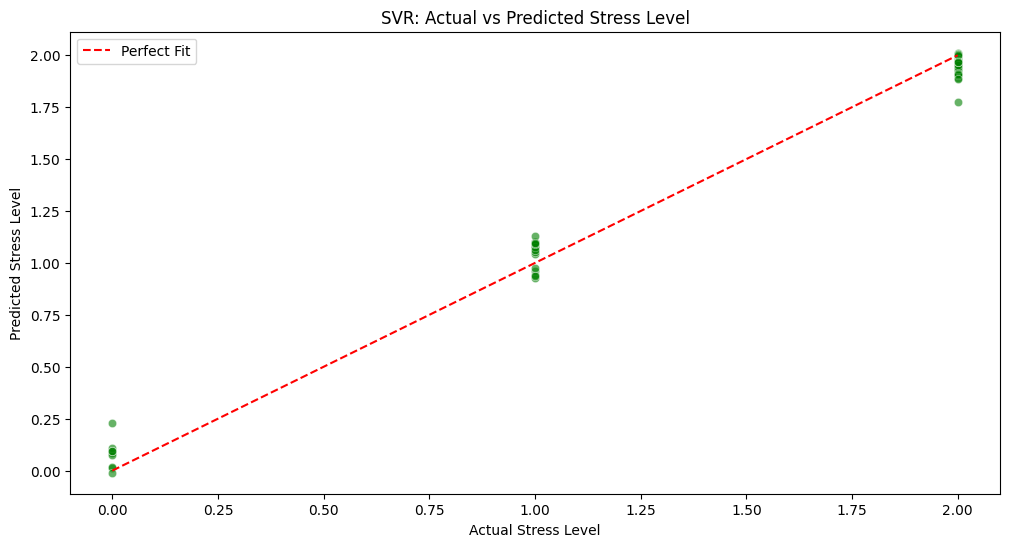

In [443]:
plt.figure(figsize=(12, 6))
sns.scatterplot(x=y_test, y=svr_pred, color="green", alpha=0.6)
plt.plot([min(y_test), max(y_test)], [min(y_test), max(y_test)], linestyle='--', color='red', label="Perfect Fit")
plt.xlabel("Actual Stress Level")
plt.ylabel("Predicted Stress Level")
plt.title("SVR: Actual vs Predicted Stress Level")
plt.legend()
plt.show()


### KNN Classifier

In [444]:
knn = KNeighborsClassifier()
knn.fit(X_train, y_train)

KNeighborsClassifier()

In [445]:
knn.score(X_test,y_test)
knn_pred = knn.predict(X_test)

matrix = confusion_matrix(y_test, knn_pred)

print("Confusion Matrix:")
print(matrix)

Confusion Matrix:
[[ 7  0  2]
 [ 0 24  6]
 [ 0  0 52]]


In [446]:
report = classification_report(y_test, knn_pred)

print("Classification Report:")
print(report)

print("The test accuracy of KNN Classifier model is:", accuracy_score(y_test, knn_pred) * 100, "%")

Classification Report:
              precision    recall  f1-score   support

           0       1.00      0.78      0.88         9
           1       1.00      0.80      0.89        30
           2       0.87      1.00      0.93        52

    accuracy                           0.91        91
   macro avg       0.96      0.86      0.90        91
weighted avg       0.92      0.91      0.91        91

The test accuracy of KNN Classifier model is: 91.20879120879121 %


### Random Forest Classifier

In [447]:
random_forest = RandomForestClassifier(n_estimators=13)
random_forest.fit(X_train,y_train)

RandomForestClassifier(n_estimators=13)

In [448]:
random_forest.score(X_test,y_test)
random_forest_pred = random_forest.predict(X_test)

matrix = confusion_matrix(y_test, random_forest_pred)

print("Confusion Matrix:")
print(matrix)

Confusion Matrix:
[[ 9  0  0]
 [ 0 30  0]
 [ 0  0 52]]


In [449]:
report = classification_report(y_test, random_forest_pred)

print("Classification Report:")
print(report)

print("The test accuracy of Random Forest Classifier model is:", accuracy_score(y_test, random_forest_pred) * 100, "%")

Classification Report:
              precision    recall  f1-score   support

           0       1.00      1.00      1.00         9
           1       1.00      1.00      1.00        30
           2       1.00      1.00      1.00        52

    accuracy                           1.00        91
   macro avg       1.00      1.00      1.00        91
weighted avg       1.00      1.00      1.00        91

The test accuracy of Random Forest Classifier model is: 100.0 %


### Decision Tree Classifier

In [450]:
X = merged_classification[["Sleep efficiency", "Sleep duration", "REM sleep percentage", 
               "Deep sleep percentage", "Light sleep percentage", "Heart_Rate_Variability"]]

y = merged_classification["Stress_Level_Cat"]

dt_model = DecisionTreeClassifier(random_state=42)
dt_model.fit(X_train, y_train)

dt_predicted = dt_model.predict(X_test)


In [451]:
dt_conf = confusion_matrix(y_test, dt_predicted)
print("Confusion Matrix (Decision Tree):\n", dt_conf)

dt_cr = classification_report(y_test, dt_predicted)
print("Classification Report (Decision Tree):\n", dt_cr)

dt_accuracy = accuracy_score(y_test, dt_predicted) * 100
print("The test accuracy of Decision Tree Classifier is:", dt_accuracy, "%")

Confusion Matrix (Decision Tree):
 [[ 9  0  0]
 [ 0 30  0]
 [ 0  0 52]]
Classification Report (Decision Tree):
               precision    recall  f1-score   support

           0       1.00      1.00      1.00         9
           1       1.00      1.00      1.00        30
           2       1.00      1.00      1.00        52

    accuracy                           1.00        91
   macro avg       1.00      1.00      1.00        91
weighted avg       1.00      1.00      1.00        91

The test accuracy of Decision Tree Classifier is: 100.0 %


## Pre-loading datasets with data from sleep tracker smartwatch

In [452]:
tracker_data_november = pd.read_csv("sleep_data_sleep_tracker/november.csv")
tracker_data_december = pd.read_csv("sleep_data_sleep_tracker/december.csv")
tracker_data_january = pd.read_csv("sleep_data_sleep_tracker/january.csv")
tracker_data_february = pd.read_csv("sleep_data_sleep_tracker/february.csv")
tracker_data_march = pd.read_csv("sleep_data_sleep_tracker/march.csv")
tracker_data_april = pd.read_csv("sleep_data_sleep_tracker/april.csv")

tracker_data = {
    "november": tracker_data_november,
    "december": tracker_data_december,
    "january": tracker_data_january,
    "february": tracker_data_february,
    "march": tracker_data_march,
    "april": tracker_data_april
}

In [453]:
def predict_per_month(df):
    date_str = df.iloc[1, 1]
    date = pd.to_datetime(date_str, format="%m/%d/%Y")
    month = date.strftime("%B")
    df.columns = df.columns.str.strip()

    # Preprocess and convert the smartwatch sleep tracker data into data fitting the trained model
    def convert_time_to_hours(time_str):
        try:
            h, m, s = map(int, time_str.split(':'))
            return h + m / 60 + s / 3600
        except:
            return None

    def convert_percentage(perc_str):
        try:
            return float(perc_str.strip('%'))
        except:
            return None

    df["SLEEP SCORE"] = pd.to_numeric(df["SLEEP SCORE"], errors='coerce')
    df["HOURS OF SLEEP"] = df["HOURS OF SLEEP"].apply(convert_time_to_hours)
    df["REM SLEEP"] = df["REM SLEEP"].apply(convert_percentage)
    df["DEEP SLEEP"] = df["DEEP SLEEP"].apply(convert_percentage)
    df["HEART RATE BELOW RESTING"] = df["HEART RATE BELOW RESTING"].apply(convert_percentage)

    df.rename(columns={
        "SLEEP SCORE": "Sleep efficiency",
        "HOURS OF SLEEP": "Sleep duration",
        "REM SLEEP": "REM sleep percentage",
        "DEEP SLEEP": "Deep sleep percentage",
        "HEART RATE BELOW RESTING": "Heart_Rate_Variability"
    }, inplace=True)

    # Fill missing column "Light sleep percentage" in the dataset from smartwatch tracker with mean value from training data
    df["Light sleep percentage"] = np.mean(merged_classification["Light sleep percentage"])

    df_features = df[["Sleep efficiency", "Sleep duration", "REM sleep percentage", 
                    "Deep sleep percentage", "Light sleep percentage", "Heart_Rate_Variability"]]

    predicted_stress_levels = dt_model.predict(df_features)

    df["Predicted Stress Level"] = label_encoder.inverse_transform(predicted_stress_levels)

    print(df[["Sleep efficiency", "Sleep duration", "REM sleep percentage", 
            "Deep sleep percentage", "Heart_Rate_Variability", "Predicted Stress Level"]])
    print(df.head(20))
    plt.figure(figsize=(8, 5))
    stress_counts = df["Predicted Stress Level"].value_counts()
    plt.bar(stress_counts.index, stress_counts.values, color=['green', 'red', 'orange'])
    plt.xlabel("Predicted Stress Level")
    plt.ylabel("Count of Days")
    plt.title("Distribution of Predicted Stress Levels")
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.show()


    stress_color_map = {"Low": "green", "Medium": "orange", "High": "red"}
    stress_colors = df["Predicted Stress Level"].map(stress_color_map)

    plt.figure(figsize=(12, 5))

    plt.plot(df.index, df["Sleep efficiency"], label="Sleep Efficiency", linestyle="-", color="blue")

    for i in range(len(df)):
        plt.scatter(i, df["Sleep efficiency"].iloc[i], color=stress_colors.iloc[i], edgecolors="black", s=80)

    plt.plot(df.index, df["Heart_Rate_Variability"], label="Heart Rate Variability", linestyle="--", color="purple")

    for i in range(len(df)):
        plt.scatter(i, df["Heart_Rate_Variability"].iloc[i], color=stress_colors.iloc[i], edgecolors="black", s=80, alpha=0.7)

    plt.xlabel(f"Days in {month}")
    plt.ylabel("Sleep Efficiency Score")
    plt.title(f"Sleep Efficiency Trend Over Time with Predicted Stress Levels in {month}")


    plt.grid(axis='both', linestyle='--', alpha=0.5)

    plt.show()
    
    return df


    Sleep efficiency  Sleep duration  REM sleep percentage  \
0                 88        8.100000                  20.0   
1                 83        7.950000                  12.0   
2                 81        7.100000                  13.0   
3                 86        7.066667                  19.0   
4                 81        9.400000                  17.0   
..               ...             ...                   ...   
25                87        8.750000                  22.0   
26                86        7.883333                  24.0   
27                83        6.216667                  22.0   
28                89        7.733333                  18.0   
29                78        6.800000                  12.0   

    Deep sleep percentage  Heart_Rate_Variability Predicted Stress Level  
0                    13.0                    84.0                 Medium  
1                    18.0                    90.0                   High  
2                    22.0     

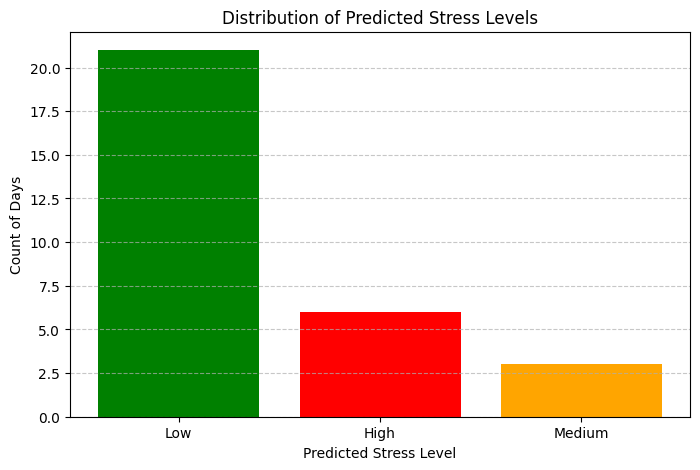

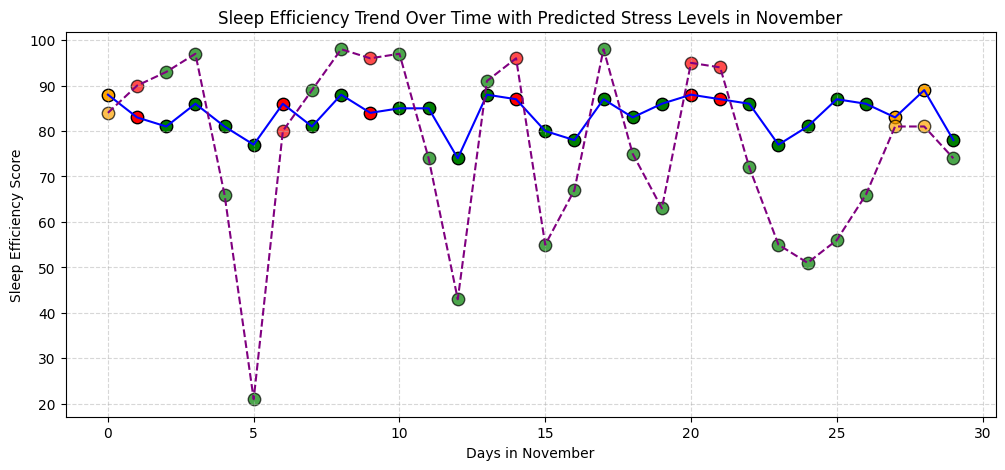

In [454]:
november = predict_per_month(tracker_data_november)

    Sleep efficiency  Sleep duration  REM sleep percentage  \
0                 91        7.550000                  23.0   
1                 81        7.283333                  16.0   
2                 80        7.283333                  15.0   
3                 85        8.383333                  20.0   
4                 82        7.316667                  20.0   
..               ...             ...                   ...   
26                83        7.100000                  20.0   
27                85        6.950000                  20.0   
28                91        7.383333                  26.0   
29                87        7.800000                  22.0   
30                89        8.150000                  23.0   

    Deep sleep percentage  Heart_Rate_Variability Predicted Stress Level  
0                    19.0                    98.0                   High  
1                    13.0                    94.0                   High  
2                    17.0     

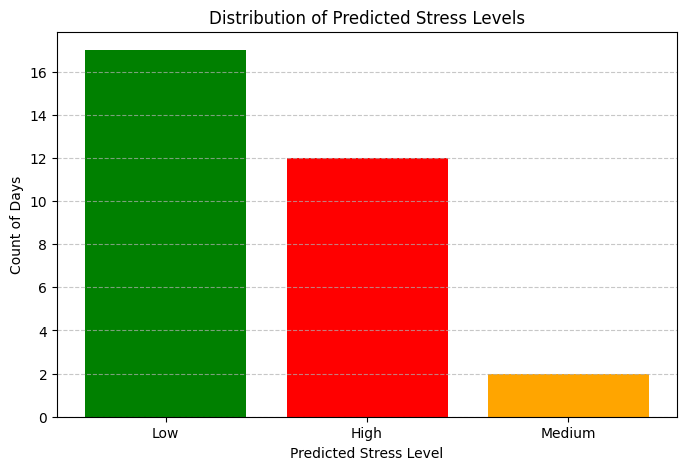

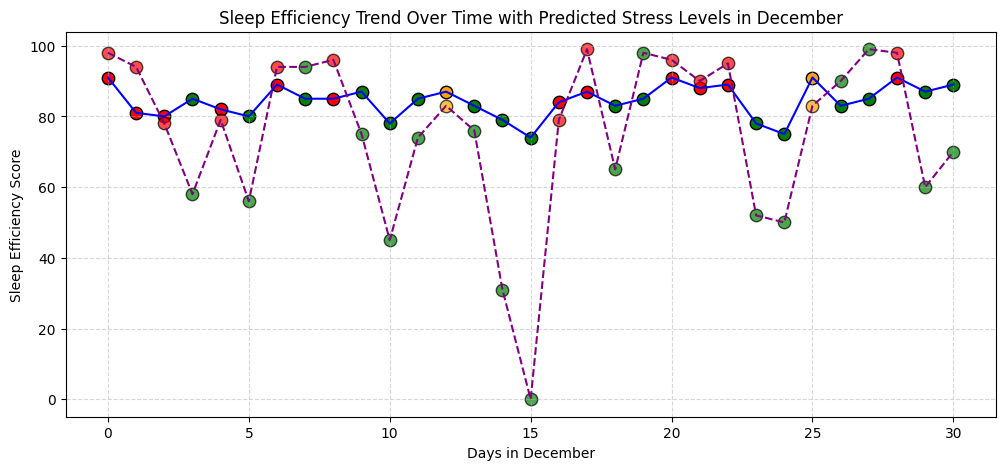

In [455]:
december = predict_per_month(df = tracker_data_december)

    Sleep efficiency  Sleep duration  REM sleep percentage  \
0                 63        4.216667                  15.0   
1                 90        8.150000                  22.0   
2                 83        7.450000                  16.0   
3                 90        7.416667                  19.0   
4                 81        7.166667                  18.0   
..               ...             ...                   ...   
26                88        6.866667                  26.0   
27                91        7.700000                  20.0   
28                87        7.616667                  22.0   
29                80        8.450000                  12.0   
30                82        7.350000                  16.0   

    Deep sleep percentage  Heart_Rate_Variability Predicted Stress Level  
0                    18.0                     0.0                    Low  
1                    18.0                    92.0                   High  
2                    13.0     

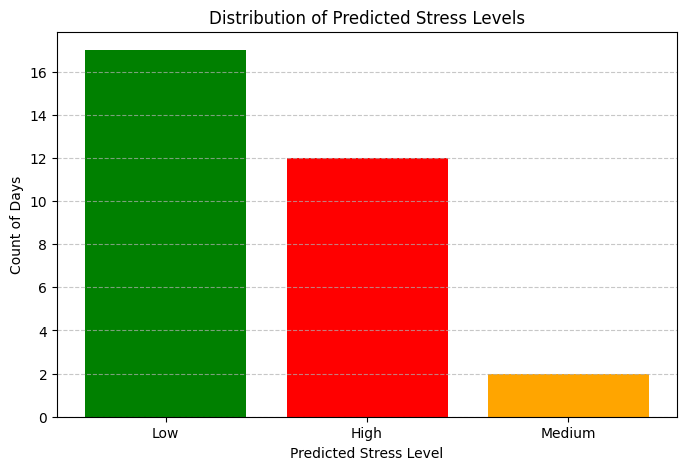

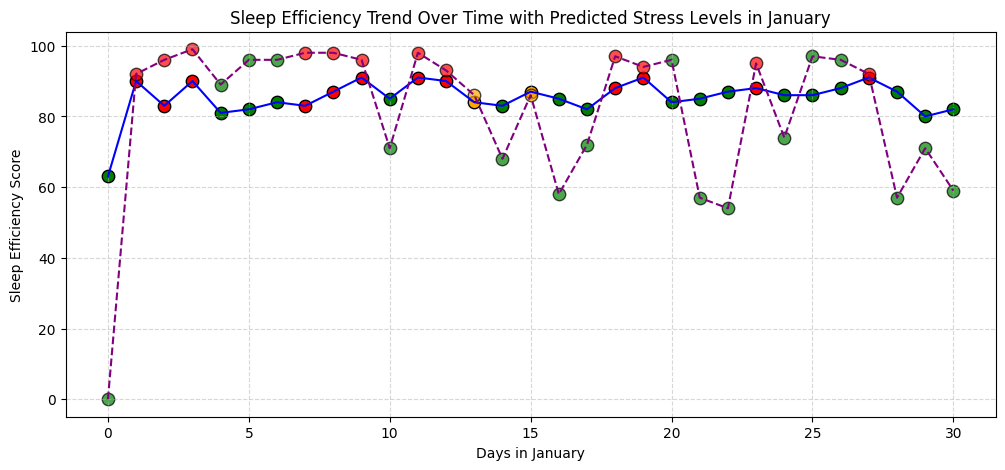

In [456]:
january = predict_per_month(df = tracker_data_january)

    Sleep efficiency  Sleep duration  REM sleep percentage  \
0                 87        7.500000                  18.0   
1                 90        7.450000                  20.0   
2                 66        5.650000                  16.0   
3                 87        9.216667                  18.0   
4                 85        6.833333                  23.0   
..               ...             ...                   ...   
23                84        7.300000                  19.0   
24                90        7.766667                  20.0   
25                82        8.033333                  16.0   
26                85        8.900000                  18.0   
27                82        7.950000                  19.0   

    Deep sleep percentage  Heart_Rate_Variability Predicted Stress Level  
0                    17.0                    98.0                   High  
1                    18.0                    88.0                 Medium  
2                     0.0     

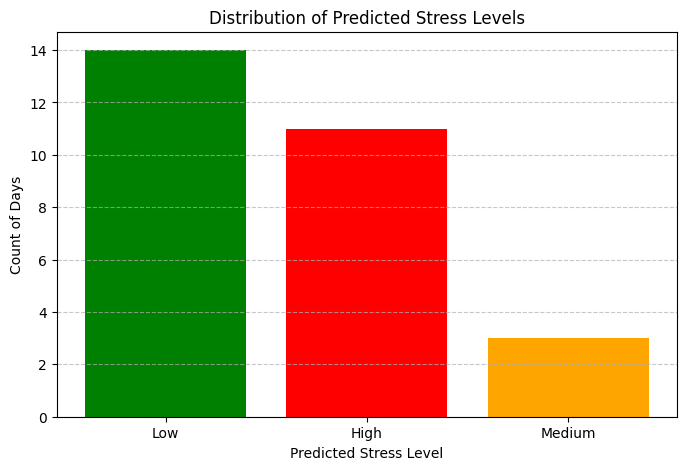

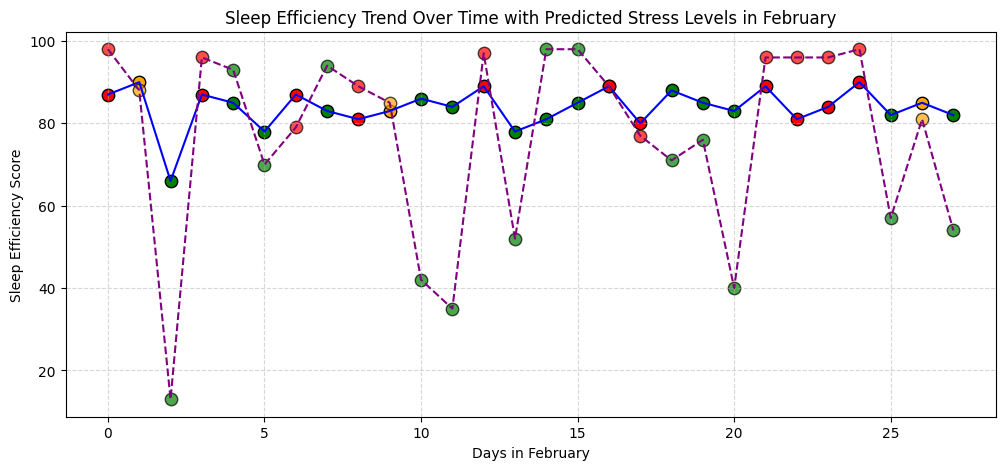

In [457]:
february = predict_per_month(df = tracker_data_february)

    Sleep efficiency  Sleep duration  REM sleep percentage  \
0               81.0        6.783333                  19.0   
1               86.0        7.600000                  14.0   
2               83.0        7.983333                  20.0   
3               84.0        8.483333                  18.0   
4               87.0        8.500000                  20.0   
..               ...             ...                   ...   
26              86.0        7.050000                  20.0   
27              80.0        6.550000                  14.0   
28              86.0        6.983333                  22.0   
29              87.0        6.566667                  20.0   
30              91.0        7.633333                  30.0   

    Deep sleep percentage  Heart_Rate_Variability Predicted Stress Level  
0                    15.0                    91.0                    Low  
1                    17.0                    97.0                   High  
2                    13.0     

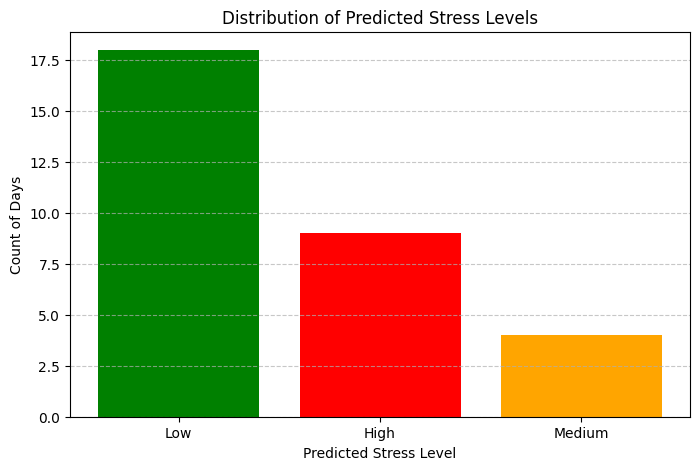

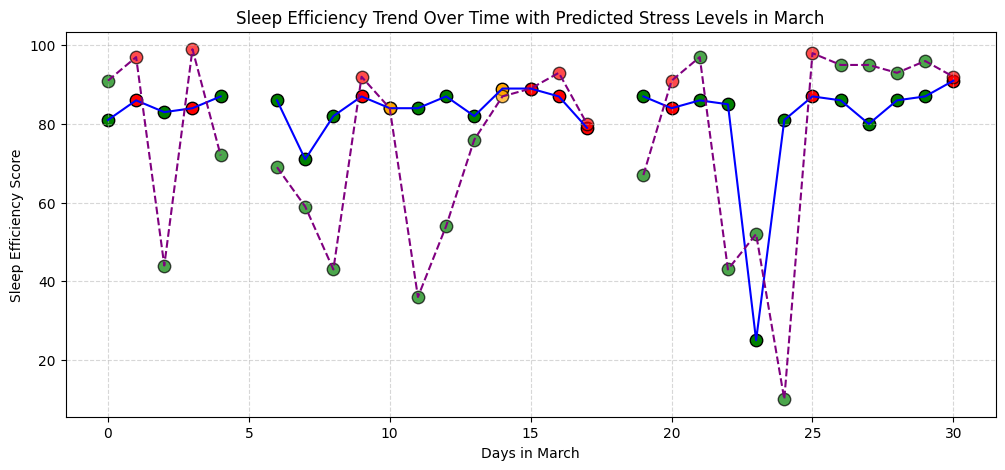

In [458]:
march = predict_per_month(df = tracker_data_march)

    Sleep efficiency  Sleep duration  REM sleep percentage  \
0                 90        7.366667                  18.0   
1                 89        8.666667                  21.0   
2                 81        8.866667                  21.0   
3                 83        6.833333                  17.0   
4                 84        6.950000                  18.0   
..               ...             ...                   ...   
25                85        7.300000                  22.0   
26                90        7.566667                  24.0   
27                87        6.900000                  21.0   
28                86        7.750000                  19.0   
29                89        7.183333                  22.0   

    Deep sleep percentage  Heart_Rate_Variability Predicted Stress Level  
0                    21.0                    98.0                   High  
1                    21.0                    73.0                    Low  
2                    17.0     

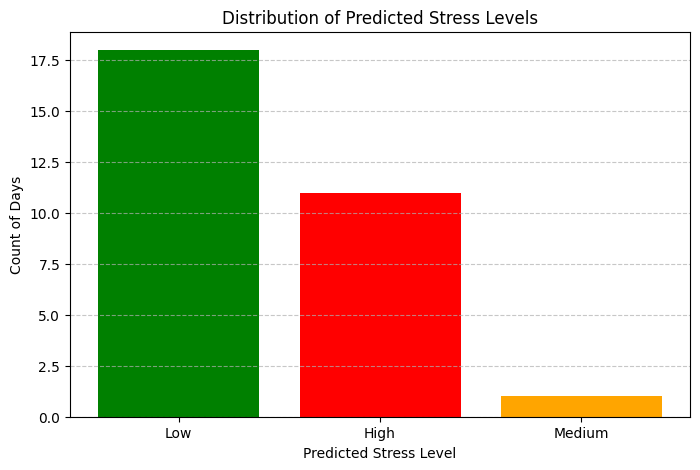

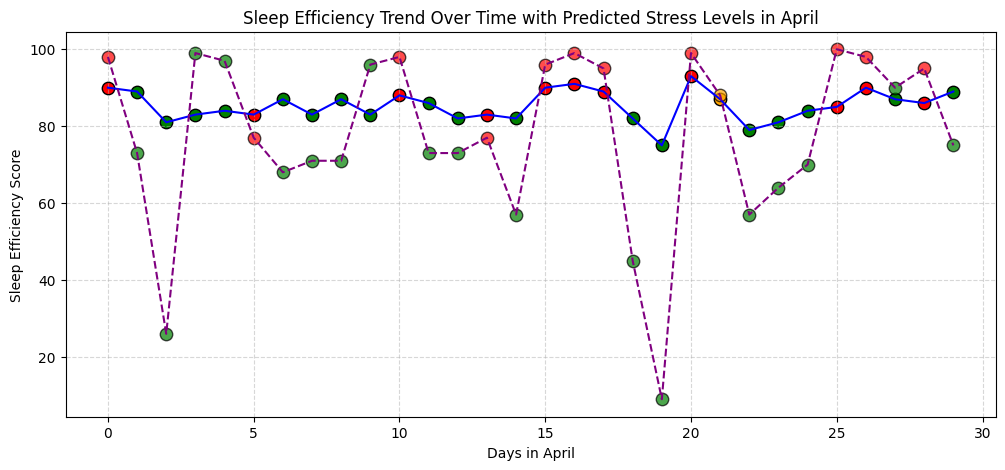

In [459]:
april = predict_per_month(df = tracker_data_april)